# 06 · Evaluación comparativa y sensibilidad

> Todo **simulado**: líneas y empresas ficticias, fraude plantado. Los resultados muestran qué tan bien funcionan los *métodos* en un escenario controlado,
> no qué pasa en el sistema real. Con datos reales, un método solo produciría "anomalías a revisar".

Hasta acá evaluamos cada método con su propia ventana, su propio umbral y su propio conjunto de líneas, así que **los números no eran comparables**.
Esta etapa los pone en pie de igualdad.

## Protocolo unificado (fijado antes de mirar el barrido)
1. **Misma información:** todos deciden con datos hasta **junio de 2026** (6 meses de fraude).
2. **Mismo criterio de umbral:** cada método calibra con un *placebo* sin fraude para marcar a lo sumo ~5 % de las líneas inocentes.
3. **Misma verdad:** línea "con fraude" = tiene al menos un mes de fraude activo en la ventana.
4. **Mismo conjunto:** la comparación directa usa solo las líneas que **todos** los métodos pueden evaluar. Aparte reportamos qué parte de *todas* las líneas con fraude cubre cada uno.

Detectores comparados: **01** quiebres (ruptures) · **02** control sintético · **03** coherencia geográfica · **04a** Isolation Forest · **04b** LOF.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200)
b = pd.read_parquet('../data/processed/barrido.parquet')
ORDEN = ['01 Quiebres', '02 Control sintético', '03 Coherencia geográfica', '04a Isolation Forest', '04b LOF']
COL = dict(zip(ORDEN, ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']))
print(f'{b.semilla.nunique()} semillas × {b.magnitud.nunique()} magnitudes × {b.metodo.nunique()} métodos')
b.groupby('magnitud').efecto_tarifa.mean().mul(100).round(2).rename('aumento de la tarifa media (%)').to_frame().T

3 semillas × 9 magnitudes × 5 métodos


magnitud,0.010,0.020,0.030,0.050,0.075,0.100,0.150,0.200,0.300
aumento de la tarifa media (%),0.14,0.28,0.41,0.69,1.04,1.38,2.07,2.76,4.14


La primera fila traduce la magnitud del fraude (fracción de viajes bajos que se corre hacia arriba) a su efecto sobre lo que ve un analista: **el aumento de la tarifa media**. Un fraude del 5 % de viajes corridos mueve la tarifa media apenas ≈ 0,7 %; el del 20 %, ≈ 2,8 %.

## 1. Caso base (magnitud 20 %, semilla 42)

In [2]:
base = b[(b.magnitud == .20) & (b.semilla == 42)].set_index('metodo').loc[ORDEN]
print(f"Líneas evaluables por todos: {int(base.n_comun.iloc[0])} | con fraude entre ellas: {int(base.expuestas_comun.iloc[0])}")
t = base[['TP', 'FP', 'FN', 'TN']].copy()
t['recall'] = base.recall.map('{:.0%}'.format); t['precisión'] = base.precision.map('{:.0%}'.format); t['% falsas alarmas'] = base.fpr.map('{:.1%}'.format)
t['AUC'] = base.auc.round(3); t['recall sobre TODAS las expuestas'] = base.recall_sobre_todas_expuestas.map('{:.0%}'.format)
t

Líneas evaluables por todos: 270 | con fraude entre ellas: 19


,TP,FP,FN,TN,recall,precisión,% falsas alarmas,AUC,recall sobre TODAS las expuestas
metodo,,,,,,,,,
01 Quiebres,19,24,0,227,100%,44%,9.6%,0.997,100%
02 Control sintético,19,19,0,232,100%,50%,7.6%,1.000,73%
03 Coherencia geográfica,11,4,8,247,58%,73%,1.6%,0.936,58%
04a Isolation Forest,7,18,12,233,37%,28%,7.2%,0.912,27%
04b LOF,17,5,2,246,89%,77%,2.0%,0.966,85%


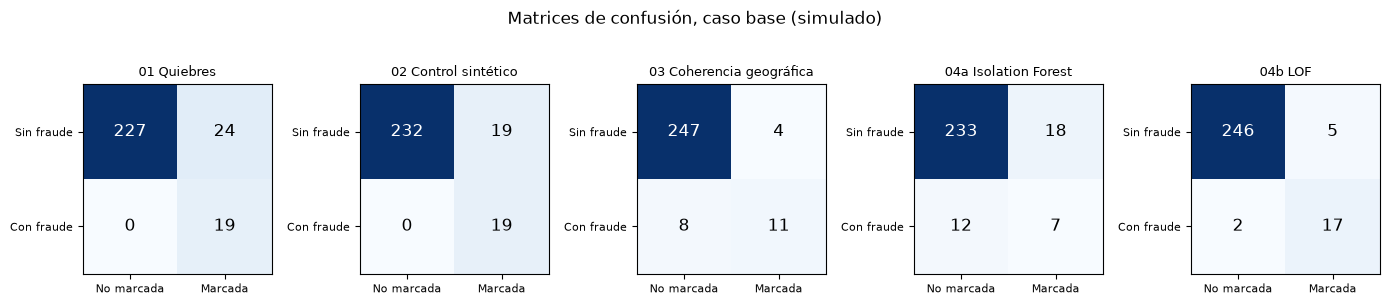

In [3]:
fig, axs = plt.subplots(1, 5, figsize=(14, 2.9))
for ax, m in zip(axs, ORDEN):
    r = base.loc[m]; M_ = np.array([[r.TN, r.FP], [r.FN, r.TP]])
    ax.imshow(M_, cmap='Blues', vmax=max(M_.max(), 1))
    for i in range(2):
        for j in range(2): ax.text(j, i, int(M_[i, j]), ha='center', va='center', color='white' if M_[i, j] > M_.max() * .5 else 'black', fontsize=12)
    ax.set_xticks([0, 1], ['No marcada', 'Marcada'], fontsize=8); ax.set_yticks([0, 1], ['Sin fraude', 'Con fraude'], fontsize=8); ax.set_title(m, fontsize=9)
plt.suptitle('Matrices de confusión, caso base (simulado)', y=1.03); plt.tight_layout()
plt.savefig('../outputs/figures/eval_matrices_confusion.png', dpi=150, bbox_inches='tight'); plt.show()

**Cómo leerlo:** con un fraude de 20 %, el **01 y el 02** detectan todas las líneas evaluables, pero con muchas falsas alarmas (9,6 % y 7,6 % de las inocentes: decenas de líneas), por lo que la precisión ronda el 45-50 %. **LOF** detecta el 89 % con apenas 2 % de falsas alarmas (precisión 77 %).
La **coherencia geográfica** detecta algo más de la mitad (58 %) con pocas falsas alarmas, e **Isolation Forest** el 37 %. La precisión no es alta aunque el recall sea alto, porque hay muchas más líneas inocentes que culpables.

## 2. Sensibilidad: ¿desde qué magnitud deja de funcionar cada método?
Recall (de las líneas con fraude, cuántas marca) en función de la magnitud, con el umbral fijado para ~5 % de falsas alarmas. Línea = promedio de 3 semillas; banda = mínimo y máximo.

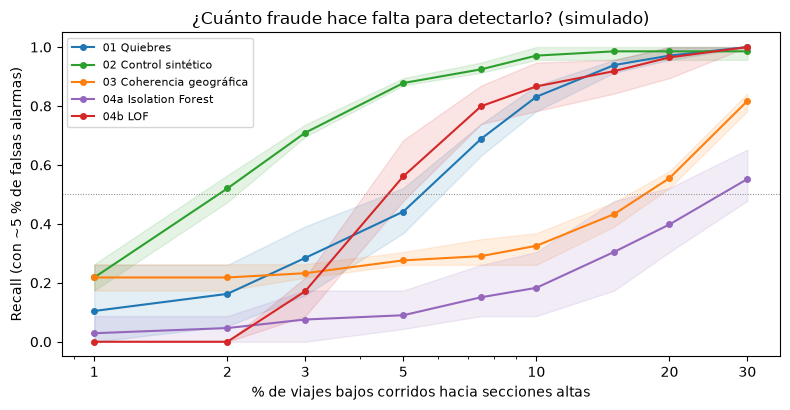

In [4]:
def curva(col, ax, ylabel, ref=None):
    for m in ORDEN:
        g = b[b.metodo == m].groupby('magnitud')[col].agg(['mean', 'min', 'max'])
        ax.plot(g.index * 100, g['mean'], marker='o', ms=4, color=COL[m], label=m); ax.fill_between(g.index * 100, g['min'], g['max'], color=COL[m], alpha=.12)
    if ref is not None: ax.axhline(ref, color='k', ls='--', lw=.7)
    ax.set_xscale('log'); ax.set_xticks([1, 2, 3, 5, 10, 20, 30], ['1', '2', '3', '5', '10', '20', '30']); ax.set_xlabel('% de viajes bajos corridos hacia secciones altas'); ax.set_ylabel(ylabel)
fig, ax = plt.subplots(figsize=(8, 4.2)); curva('recall', ax, 'Recall (con ~5 % de falsas alarmas)'); ax.axhline(.5, color='gray', ls=':', lw=.7)
ax.legend(fontsize=8); ax.set_title('¿Cuánto fraude hace falta para detectarlo? (simulado)')
plt.tight_layout(); plt.savefig('../outputs/figures/eval_sensibilidad_recall.png', dpi=150); plt.show()

**Lectura de las curvas:**
- **El control sintético (02) es el más sensible**: con 1 % de viajes corridos (tarifa media +0,14 %) detecta el 22 % de las líneas, con 2 % el 52 %, y con 5 % el 88 %.
- **LOF** llega al 56 % con 5 % de viajes corridos y al 87 % con 10 %. El **01** necesita algo más: 69 % con 7,5 % y 83 % con 10 %.
- **La coherencia geográfica (03)** necesita 20 % para llegar al 50 % y 30 % para el 80 %. **Isolation Forest** llega al 55 % recién con 30 %.
- **El 02 tiene un techo de cobertura:** no puede evaluar líneas con poca historia, así que su recall sobre *todas* las líneas con fraude se frena en ≈ 78 %. El 01 y LOF, que cubren más, llegan a 94 % y 97 % con 30 %, y lo superan desde ~10 % de magnitud.
- **Advertencia:** la sensibilidad del 02 depende de que la simulación es limpia (sin shocks propios de cada línea). Con datos reales su ventaja probablemente se achicaría.

## 3. Ranking: ¿ordenan bien aunque el umbral falle?
El AUC mide si el método pone a las líneas con fraude por encima de las inocentes, sin depender de dónde se fije el umbral (0,5 = azar, 1 = perfecto).

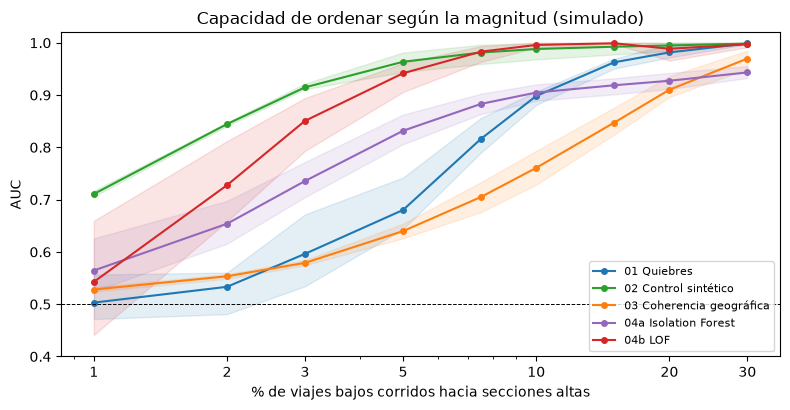

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2)); curva('auc', ax, 'AUC', ref=.5); ax.set_ylim(.4, 1.02); ax.legend(fontsize=8, loc='lower right')
ax.set_title('Capacidad de ordenar según la magnitud (simulado)'); plt.tight_layout()
plt.savefig('../outputs/figures/eval_sensibilidad_auc.png', dpi=150); plt.show()

## 4. ¿Se mantienen las falsas alarmas en ~5 %?
Chequeo de calibración: si el protocolo está bien, la tasa de falsas alarmas debería ser parecida en todas las magnitudes (el fraude no cambia a las líneas inocentes). Si crece con la magnitud, el método se contamina.

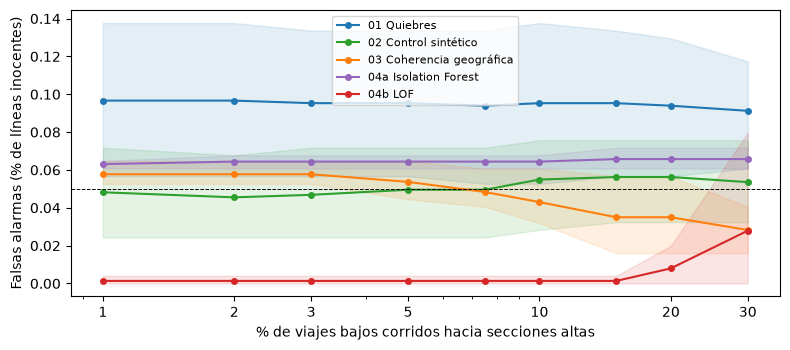

,promedio %,mín %,máx %
metodo,,,
01 Quiebres,9.5,5.3,13.8
02 Control sintético,5.1,2.4,7.6
03 Coherencia geográfica,4.6,1.6,6.5
04a Isolation Forest,6.5,6.1,7.2
04b LOF,0.5,0.0,8.0


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6)); curva('fpr', ax, 'Falsas alarmas (% de líneas inocentes)', ref=.05)
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig('../outputs/figures/eval_calibracion_fpr.png', dpi=150); plt.show()
b.groupby('metodo').fpr.agg(['mean', 'min', 'max']).loc[ORDEN].mul(100).round(1).rename(columns={'mean': 'promedio %', 'min': 'mín %', 'max': 'máx %'})

**Lectura:** **la calibración no es pareja.** El 02 (5,1 %), el 03 (4,6 %) e Isolation Forest (6,5 %) quedan cerca del 5 % buscado. El **01 queda sistemáticamente por encima** (9,5 % de promedio, entre 5,3 % y 13,8 %): su umbral del placebo es demasiado permisivo. **LOF queda por debajo** (0,5 % de promedio) pero con una corrida de 8 %: es conservador y errático a la vez.
O sea que el placebo es una aproximación, no una garantía, y comparar recalls sin mirar las falsas alarmas puede favorecer a quien más acusa de más.

## 5. Magnitud mínima detectable

In [7]:
prom = b.groupby(['metodo', 'magnitud']).agg(recall=('recall', 'mean'), efecto=('efecto_tarifa', 'mean')).reset_index()
filas = []
for m in ORDEN:
    g = prom[prom.metodo == m].sort_values('magnitud'); fila = {'método': m}
    for umbral in (.5, .8):
        ok = g[g.recall >= umbral]
        fila[f'recall ≥ {int(umbral*100)} %'] = f"{ok.magnitud.iloc[0]:.1%} (tarifa media {ok.efecto.iloc[0]:+.1%})" if len(ok) else 'no se alcanza'
    filas.append(fila)
pd.DataFrame(filas).set_index('método')

,recall ≥ 50 %,recall ≥ 80 %
método,,
01 Quiebres,7.5% (tarifa media +1.0%),10.0% (tarifa media +1.4%)
02 Control sintético,2.0% (tarifa media +0.3%),5.0% (tarifa media +0.7%)
03 Coherencia geográfica,20.0% (tarifa media +2.8%),30.0% (tarifa media +4.1%)
04a Isolation Forest,30.0% (tarifa media +4.1%),no se alcanza
04b LOF,5.0% (tarifa media +0.7%),10.0% (tarifa media +1.4%)


**Cómo leer esta tabla:** es la mínima magnitud de las probadas en que el recall promedio llega a 50 % y a 80 %. No es un umbral exacto: las magnitudes probadas son una grilla discreta.

## Lecciones
- **Ningún método domina.** El control sintético es el más sensible con fraudes chicos, pero su cobertura se frena en ~78 % de las líneas con fraude; el 01 y LOF cubren más (94-97 %) y lo superan con fraudes grandes.
- **La sensibilidad se mide en tarifa media.** Lo que un analista ve es cuánto sube la tarifa media: +0,14 % (1 % de viajes corridos) es el límite inferior probado y solo el control sintético lo capta, y apenas en parte. Con menos de +0,7 % (menos del 5 % de viajes corridos) solo el control sintético supera la mitad de las líneas, y recién desde ≈ 2 %.
- **Un detector genérico no es todo igual.** Isolation Forest rinde mal en casi todas las magnitudes. LOF, en cambio, compite con los métodos específicos (89 % de recall con 2 % de falsas alarmas en el caso base), aunque su calibración es errática.
- **La coherencia geográfica (03) sirve poco como detector** en este escenario: requiere fraudes grandes. Su valor está en que no usa la historia y es fácil de explicar.
- **Comparar métodos exige mirar falsas alarmas y cobertura, no solo recall.** El 01 parece muy bueno (recall 100 %) pero acusa a casi 1 de cada 10 inocentes.
- **Los métodos no son independientes:** el 02 usa al 01 para depurar donantes, y varios comparten el supuesto de que el pasado es limpio.

## Limitaciones de toda la evaluación
- **Simulación limpia:** no hay shocks que afecten a unas líneas y no a otras (cambios de recorrido, obras, paros, estacionalidad fuerte). Con datos reales las falsas alarmas serían mayores y el recall menor.
- **Un solo tipo de fraude:** corrimiento fijo desde una fecha. Un fraude gradual, intermitente o muy concentrado en pocos días podría comportarse distinto.
- **Tres semillas:** la banda mín-máx da una idea de la variabilidad, no un intervalo de confianza.
- **El umbral es del 5 %:** otra elección cambia la tabla (compromiso entre detectar y acusar de más).
- **Los métodos se calibraron a ojo en algunos aspectos** (ventana de 6 meses, 36 meses de ajuste del sintético): son decisiones razonables, no óptimas.